importing the libraries 

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
df = pd.read_csv("data/process_data.csv")

sns.set_theme(style="whitegrid")

print("Dataset shape:", df.shape)
print("\nDataset information:")
df.info()


Dataset shape: (10000, 14)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      100

In [3]:
sensor_columns = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

target = "Machine failure"

DESCRIPTIVE STATISTICS

In [4]:
print(df[sensor_columns].describe().T.round(2))

print("\n========== FAILURE COUNTS ==========")
print(df[target].value_counts(dropna=False))

print("\n========== FAILURE PERCENTAGES ==========")
print(
    (df[target].value_counts(normalize=True) * 100).round(2)
)

                           count     mean     std     min     25%     50%  \
Air temperature [K]      10000.0   300.00    2.00   295.3   298.3   300.1   
Process temperature [K]  10000.0   310.01    1.48   305.7   308.8   310.1   
Rotational speed [rpm]   10000.0  1538.78  179.28  1168.0  1423.0  1503.0   
Torque [Nm]              10000.0    39.99    9.97     3.8    33.2    40.1   
Tool wear [min]          10000.0   107.95   63.65     0.0    53.0   108.0   

                            75%     max  
Air temperature [K]       301.5   304.5  
Process temperature [K]   311.1   313.8  
Rotational speed [rpm]   1612.0  2886.0  
Torque [Nm]                46.8    76.6  
Tool wear [min]           162.0   253.0  

========== FAILURE COUNTS ==========
Machine failure
0    9661
1     339
Name: count, dtype: int64

========== FAILURE PERCENTAGES ==========
Machine failure
0    96.61
1     3.39
Name: proportion, dtype: float64


FAILURE DISTRIBUTION

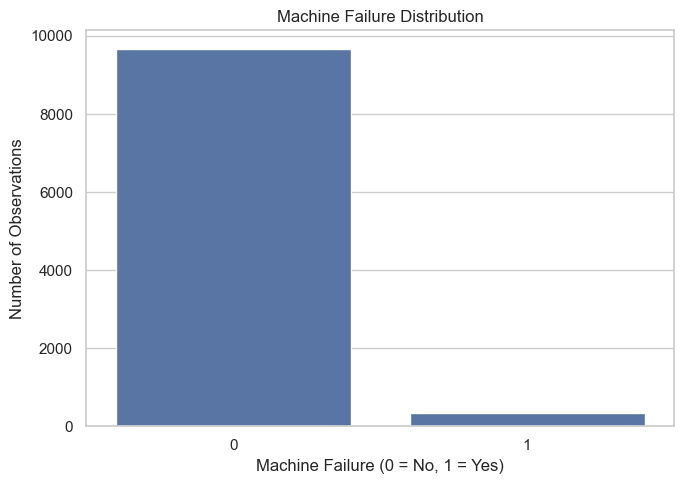

In [5]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x=target)

plt.title("Machine Failure Distribution")
plt.xlabel("Machine Failure (0 = No, 1 = Yes)")
plt.ylabel("Number of Observations")
plt.tight_layout()
plt.show()

 DISTRIBUTION OF SENSOR MEASUREMENTS

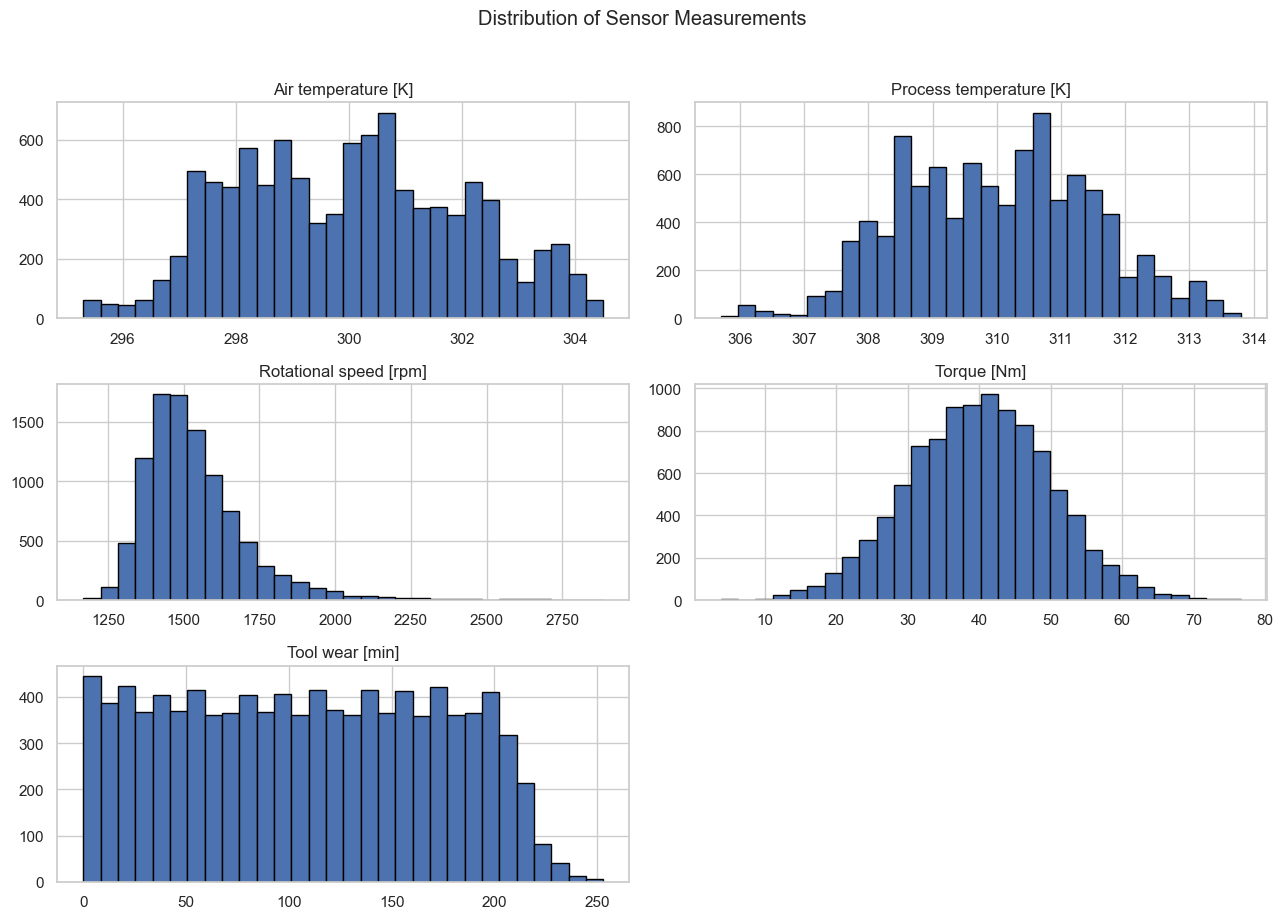

In [6]:
df[sensor_columns].hist(
    bins=30,
    figsize=(13, 9),
    edgecolor="black"
)

plt.suptitle("Distribution of Sensor Measurements", y=1.02)
plt.tight_layout()
plt.show()

FAILURE RATE BY PRODUCT TYPE


========== FAILURE RATE BY TYPE ==========
      Failure_Rate  Observations  Failures
Type                                      
H             2.09          1003        21
L             3.92          6000       235
M             2.77          2997        83


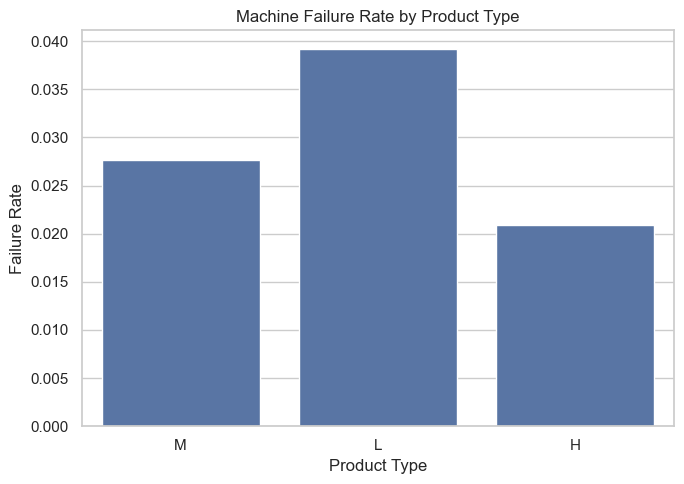

In [7]:
if "Type" in df.columns:
    failure_rate_by_type = (
        df.groupby("Type", observed=True)[target]
        .agg(["mean", "count", "sum"])
        .rename(columns={
            "mean": "Failure_Rate",
            "count": "Observations",
            "sum": "Failures"
        })
    )

    failure_rate_by_type["Failure_Rate"] *= 100

    print("\n========== FAILURE RATE BY TYPE ==========")
    print(failure_rate_by_type.round(2))

    plt.figure(figsize=(7, 5))

    sns.barplot(
        data=df,
        x="Type",
        y=target,
        errorbar=None
    )

    plt.title("Machine Failure Rate by Product Type")
    plt.xlabel("Product Type")
    plt.ylabel("Failure Rate")
    plt.tight_layout()
    plt.show()


SENSOR MEASUREMENTS BY FAILURE STATUS

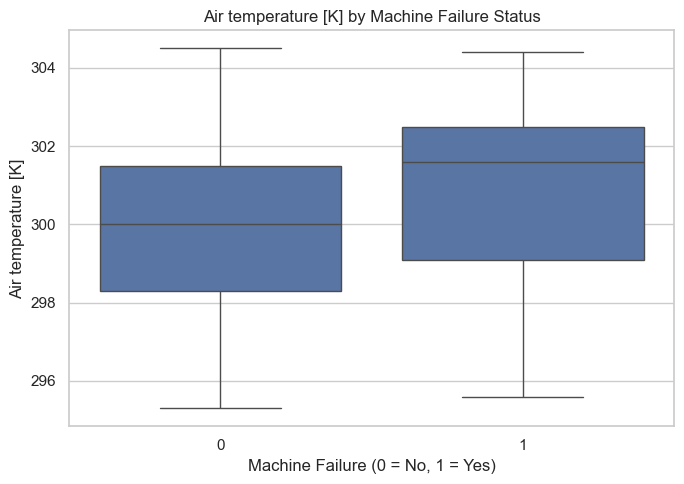

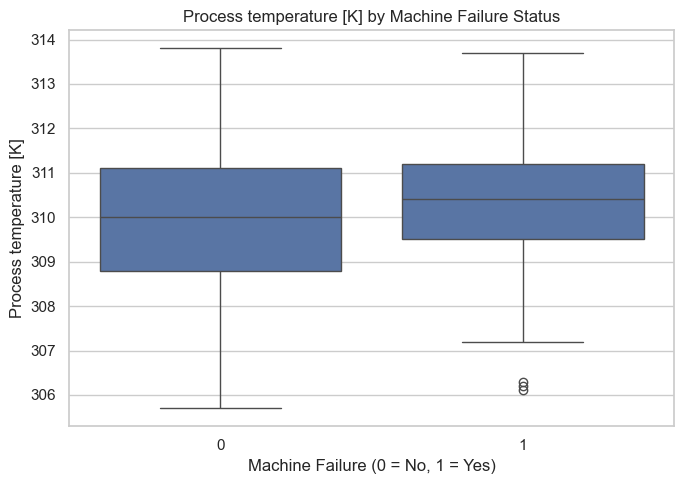

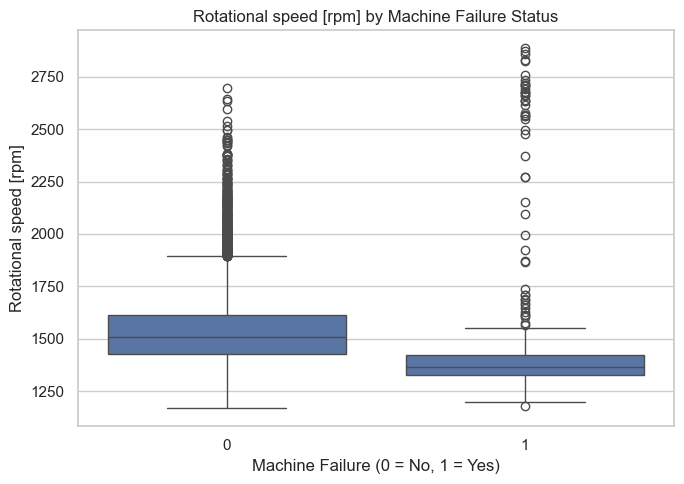

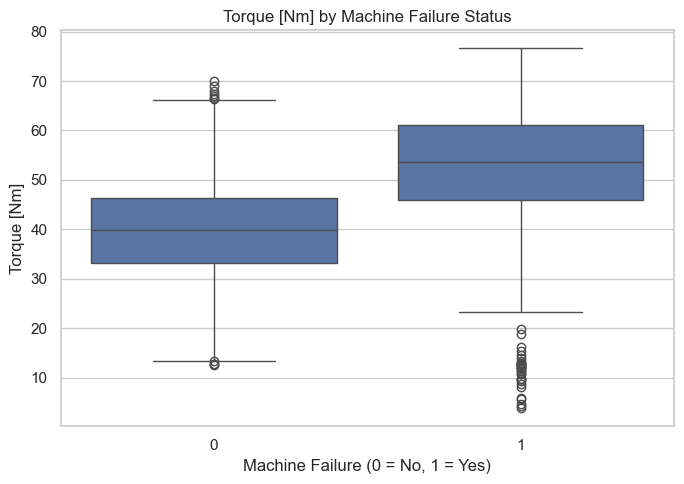

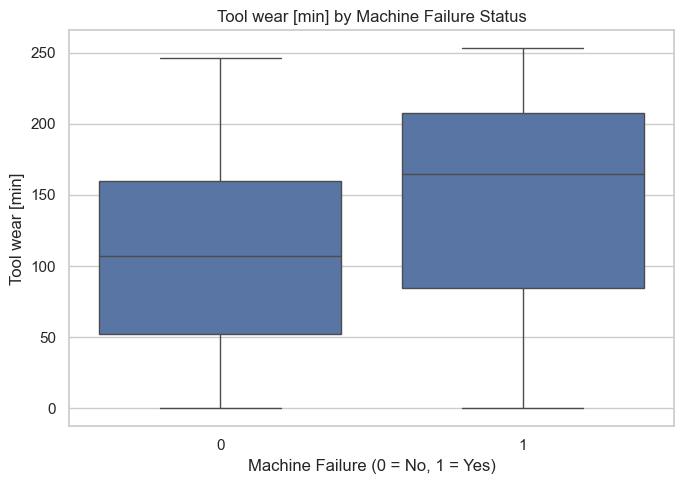

In [8]:
for column in sensor_columns:
    plt.figure(figsize=(7, 5))

    sns.boxplot(
        data=df,
        x=target,
        y=column
    )

    plt.title(f"{column} by Machine Failure Status")
    plt.xlabel("Machine Failure (0 = No, 1 = Yes)")
    plt.ylabel(column)
    plt.tight_layout()
    plt.show()

CORRELATION HEATMAP


========== CORRELATION WITH FAILURE ==========
Torque [Nm]                0.191
Tool wear [min]            0.105
Air temperature [K]        0.083
Rotational speed [rpm]    -0.044
Process temperature [K]    0.036
Name: Machine failure, dtype: float64


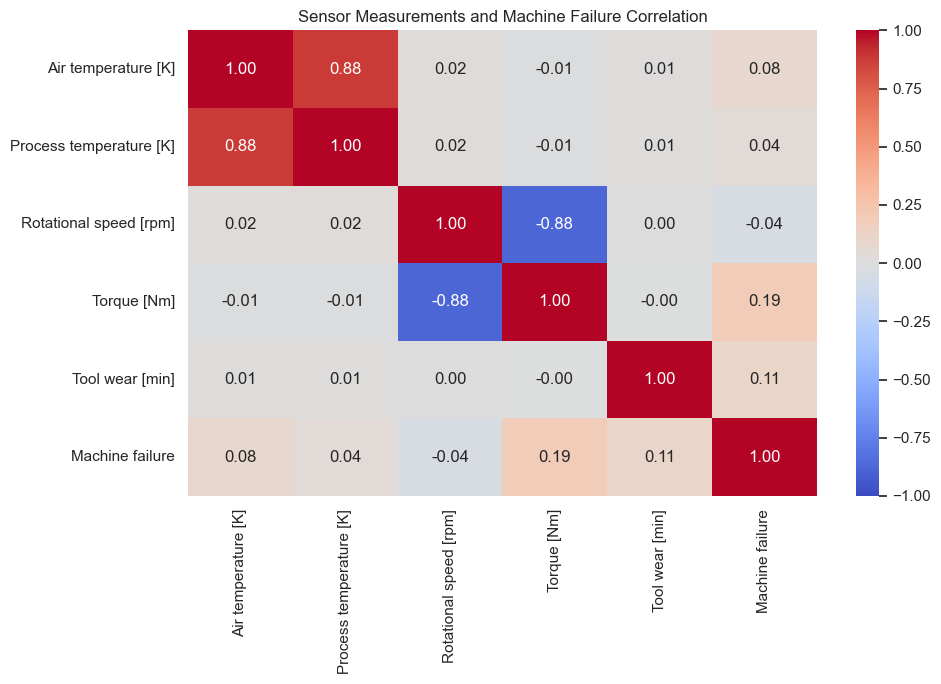

In [9]:
correlation_columns = sensor_columns + [target]
correlation_matrix = df[correlation_columns].corr()

print("\n========== CORRELATION WITH FAILURE ==========")
print(
    correlation_matrix[target]
    .drop(target)
    .sort_values(key=abs, ascending=False)
    .round(3)
)

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Sensor Measurements and Machine Failure Correlation")
plt.tight_layout()
plt.show()

ROTATIONAL SPEED VS TORQUE

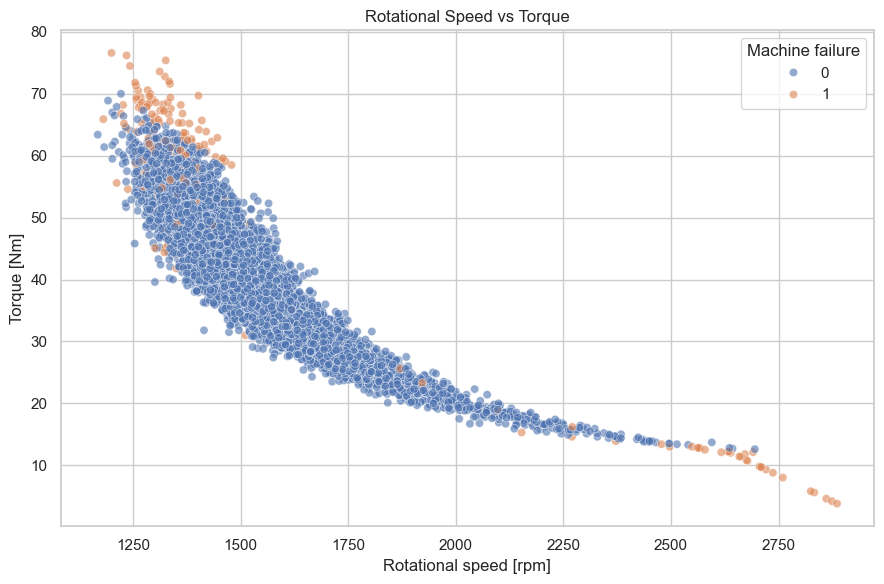

In [10]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="Rotational speed [rpm]",
    y="Torque [Nm]",
    hue=target,
    alpha=0.6
)

plt.title("Rotational Speed vs Torque")
plt.tight_layout()
plt.show()


TOOL WEAR VS FAILURE

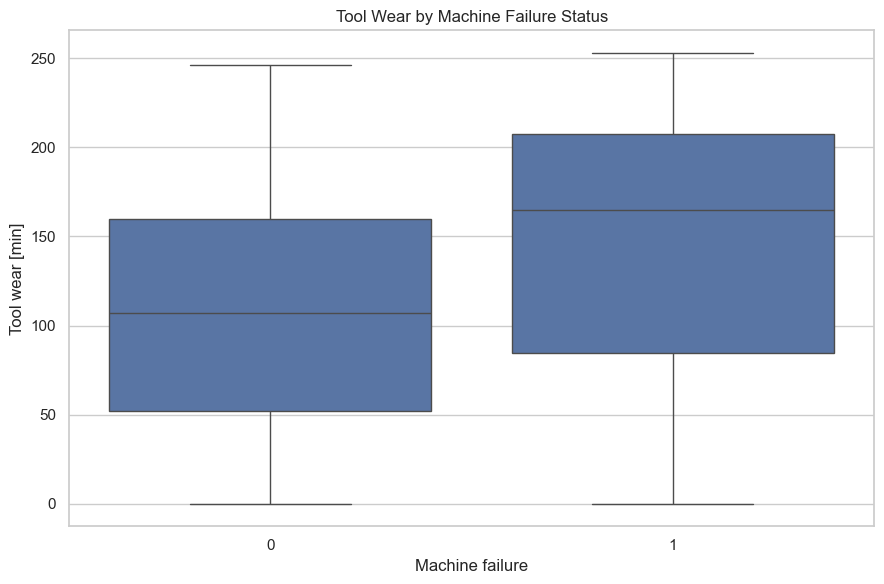

In [11]:
plt.figure(figsize=(9, 6))

sns.boxplot(
    data=df,
    x=target,
    y="Tool wear [min]"
)

plt.title("Tool Wear by Machine Failure Status")
plt.tight_layout()
plt.show()

FAILURE MODE SUMMARY


========== FAILURE MODE COUNTS ==========
HDF    115
OSF     98
PWF     95
TWF     46
RNF     19
dtype: int64


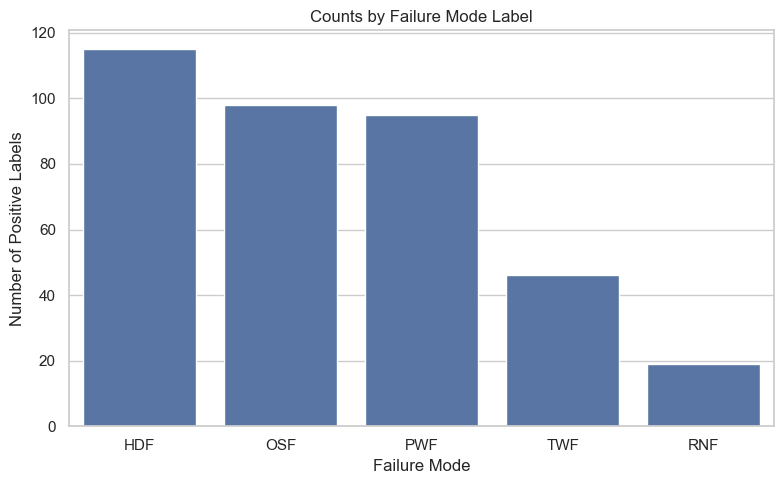

In [12]:
failure_modes = ["TWF", "HDF", "PWF", "OSF", "RNF"]

available_modes = [
    column for column in failure_modes
    if column in df.columns
]

if available_modes:
    print("\n========== FAILURE MODE COUNTS ==========")

    # These counts may overlap; they are not necessarily
    # mutually exclusive categories.
    print(df[available_modes].sum().sort_values(ascending=False))

    mode_counts = df[available_modes].sum().sort_values(
        ascending=False
    )

    plt.figure(figsize=(8, 5))

    sns.barplot(
        x=mode_counts.index,
        y=mode_counts.values
    )

    plt.title("Counts by Failure Mode Label")
    plt.xlabel("Failure Mode")
    plt.ylabel("Number of Positive Labels")
    plt.tight_layout()
    plt.show()


SAVE EDA SUMMARY

In [13]:
summary = df[sensor_columns].describe().T
summary.to_csv("eda_sensor_summary.csv")

print("\nEDA completed successfully.")
print("Summary saved to eda_sensor_summary.csv")


EDA completed successfully.
Summary saved to eda_sensor_summary.csv
